# Passed strokes

Strokes behind the simulation's best settings. For each split's best setting found by `earl_simulation.ipynb`
(section 5, `runs/<hash>/best/best_sessions.csv`), one stroke of exactly `window_s` (0.5 s) is taken from each session
and plotted from (0,0):

| Section | Sessions | Writes |
|---|---|---|
| 2. Passed strokes | the passed sessions, per split and user | `runs/<hash>/passed_strokes_<window>s/<split>/<user>/` |
| 3. Mixed | every tested session, legitimate (blue) and impostor (red) together, per split | `runs/<hash>/mixed_strokes_<window>s/<split>/` |

Nothing is matched or scored here: which sessions passed comes from the simulation. Self-contained like the
simulation notebook (no imports from `src/`); the shared code in section 1 is a copy of the simulation notebook's,
keep the two in sync by hand.

**How to use**

1. Run `earl_simulation.ipynb` first (at least sections 3–5) with the same `SETTINGS`.
2. Open this notebook with the **`.venv` kernel**, keep `SETTINGS` equal to the simulation's (it names the results
   folder `runs/<hash>/`), choose `PASSED_STROKES`, and **Run All**.

In [1]:
import hashlib
import json
import pickle
import random
import shutil
import subprocess
import time
from dataclasses import dataclass, field
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import yaml

try:
    from numba import njit, prange
except ImportError:
    raise ImportError("numba is not installed in this kernel: choose the .venv kernel, "
                      "or install it here with  %pip install numba") from None

_HERE = Path.cwd()
ROOT = next((p for p in [_HERE, _HERE / "experiment_earl", *_HERE.parents] if (p / "datasets" / "balabit").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError(f"No datasets/balabit found from {_HERE}: open this notebook from inside the repository")
RUNS = ROOT / "runs"        # every result, one folder per settings hash
CACHE_DIR = ROOT / "cache"  # DTW results reused across runs (keys hold the settings that change a score)
print("experiment folder:", ROOT)

experiment folder: /home/tin/thesis-mouse-biometrics/experiment_earl


## Settings

`SETTINGS` must equal `earl_simulation.ipynb`'s, so both use the same `runs/<hash>/` folder and session draw.

In [2]:
SETTINGS = {
    "seed": 945,                # picks the users and each user's session order once (same seed = same draw)
    "dataset_dir": "datasets/balabit/users",              # Balabit, one folder per user (relative to experiment_earl/)
    "labels_file": "datasets/balabit/public_labels.csv",  # sessions with is_illegal = 1 are dropped; None keeps all
    # chunking: cut a session into strokes
    "pause_gap_s": 0.5,         # a pause longer than this many seconds starts a new stroke (clicks also split strokes)
    "min_points": 10,           # strokes with fewer recorded points are dropped as jitter
    "min_length_px": 0,         # strokes with a shorter path (px) are dropped (0 = no filter)
    "resample_n": 64,          # every stroke is redrawn with this many evenly spaced points before matching
    # matching
    "dtw_band": 0.1,            # DTW may stretch a stroke by at most this share of resample_n
    "match_shape_ratio": 0.2,   # a session passes when at least this share of its strokes match
    "match_session_ratio": 0.5, # a user goes through when at least this share of their sessions pass
}

# One stroke per session (sections 2 and 3)
PASSED_STROKES = {
    "window_s": 0.5,  # per session: the first stroke lasting at least this long, cut to exactly this long
    "show": ["user29"],  # users whose section 2 plots and tables are also shown in the notebook; [] = none
}


## 1. Shared code

Copied from `earl_simulation.ipynb` (run folders, the Balabit loader, strokes and banded DTW). Nothing to change here.

In [3]:
RUN_KEYS = ("n_legitimate", "n_impostor", "sensitivity", "sessions_per_user")  # name a run inside its hash folder
INVALID_COORDINATE = 65535  # Balabit logging glitch, not a position


def settings_hash(config: dict) -> str:
    """6-character hash of every setting except RUN_KEYS, so runs that differ only in those sit side by side."""
    settings = {k: v for k, v in config.items() if k not in RUN_KEYS}
    return hashlib.sha1(json.dumps(settings, sort_keys=True).encode()).hexdigest()[:6]


def group_folder() -> Path:
    """runs/<hash>/ of SETTINGS: the batch runs, accuracy, best and sweep of these settings."""
    return RUNS / settings_hash(SETTINGS)


def run_folder(config: dict) -> Path:
    name = "_".join(f"{config[k]:.2f}" if k == "sensitivity" else f"{config[k]:g}" for k in RUN_KEYS)
    return RUNS / settings_hash(config) / name


def create_run(folder: Path, config: dict) -> None:
    """Run folder with its settings (config.yaml) and run.json (creation time, git commit)."""
    folder.mkdir(parents=True, exist_ok=True)
    (folder / "config.yaml").write_text(yaml.safe_dump(config, sort_keys=False))
    try:
        commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True,
                                cwd=ROOT, check=True).stdout.strip()
    except (OSError, subprocess.CalledProcessError):
        commit = None
    (folder / "run.json").write_text(json.dumps(
        {"created": datetime.now().isoformat(timespec="seconds"), "git_commit": commit}, indent=2) + "\n")


def write_csv(table: pd.DataFrame, path: Path, index: bool = False) -> None:
    """Write via a temporary file, so an interrupted write never leaves a half file."""
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(".tmp")
    table.to_csv(tmp, index=index)
    tmp.replace(path)


_ILLEGAL: dict = {}


def illegal_sessions(config: dict) -> set[str]:
    """Sessions that labels_file marks is_illegal = 1: recorded by someone else in this user's folder."""
    if not config.get("labels_file"):
        return set()
    if config["labels_file"] not in _ILLEGAL:
        labels = pd.read_csv(ROOT / config["labels_file"])
        _ILLEGAL[config["labels_file"]] = set(labels.loc[labels["is_illegal"] == 1, "filename"])
    return _ILLEGAL[config["labels_file"]]


def list_users(config: dict) -> list[str]:
    return sorted(p.name for p in (ROOT / config["dataset_dir"]).iterdir() if p.is_dir())


def list_sessions(config: dict, user: str) -> list[Path]:
    """Every session of `user` (Balabit's training and test files merged per user, adviser 2026-10-14)."""
    illegal = illegal_sessions(config)
    return sorted(p for p in (ROOT / config["dataset_dir"] / user).iterdir() if p.is_file() and p.name not in illegal)


def session_pool(config: dict, user: str, seed: int) -> list[str]:
    """Session names of `user`, shuffled once from `seed`, so step k+1 contains step k."""
    names = [p.name for p in list_sessions(config, user)]
    random.Random(f"{seed}-{user}").shuffle(names)
    return names


def max_sessions(config: dict) -> int:
    """Largest session count every user can supply."""
    return min(len(list_sessions(config, user)) for user in list_users(config))


def draw_users(config: dict, seed: int) -> tuple[list[str], list[str], dict[str, list[str]]]:
    """One draw from `seed`, fixed for the whole run: legitimate users in draw order, sorted impostors, and each
    user's shuffled session pool."""
    users = list_users(config)
    rng = random.Random(seed)
    legit = rng.sample(users, config["n_legitimate"])
    impostor = sorted(rng.sample([u for u in users if u not in legit], config["n_impostor"]))
    return legit, impostor, {user: session_pool(config, user, seed) for user in legit + impostor}


def load_session(path: Path) -> pd.DataFrame:
    """Columns t (seconds from the first event), x, y, button, state, in time order. Scroll rows and glitch rows
    (x or y = 65535) are dropped; the sort is stable because many Balabit timestamps tie."""
    df = pd.read_csv(path, usecols=["client timestamp", "button", "state", "x", "y"])
    df = df.rename(columns={"client timestamp": "t"}).dropna(subset=["t", "x", "y"])
    df = df[(df["button"] != "Scroll") & (df["x"] < INVALID_COORDINATE) & (df["y"] < INVALID_COORDINATE)]
    df = df.sort_values("t", kind="stable").reset_index(drop=True)
    df["t"] = df["t"] - df["t"].iloc[0] if len(df) else df["t"]
    return df[["t", "x", "y", "button", "state"]]

In [4]:
MOVE, DRAG = 0, 1
KIND_NAMES = {MOVE: "move", DRAG: "drag"}


def path_length(chunk: np.ndarray) -> float:
    return float(np.hypot(*np.diff(chunk[:, :2], axis=0).T).sum())


def segment(df: pd.DataFrame, config: dict) -> list[tuple[np.ndarray, int]]:
    """Strokes as ([x, y, t] array, kind). A new stroke starts after a pause or any click event."""
    click = df["state"].isin(["Pressed", "Released"]).to_numpy()
    clicks_before = np.cumsum(click)
    keep = ~click
    t = df["t"].to_numpy()[keep]
    if not len(t):
        return []
    xyt = np.column_stack([df["x"].to_numpy()[keep], df["y"].to_numpy()[keep], t])
    drag = df["state"].to_numpy()[keep] == "Drag"
    clicked = np.diff(clicks_before[keep], prepend=clicks_before[keep][0]) > 0
    new_chunk = (np.diff(t, prepend=t[0]) > config["pause_gap_s"]) | clicked
    starts = np.flatnonzero(new_chunk)
    starts = np.concatenate([[0], starts[starts > 0], [len(t)]])
    chunks = []
    for lo, hi in zip(starts[:-1], starts[1:]):
        if hi - lo >= config["min_points"] and path_length(xyt[lo:hi]) >= config["min_length_px"]:
            chunks.append((xyt[lo:hi], DRAG if drag[lo:hi].mean() > 0.5 else MOVE))
    return chunks


def normalize(chunk: np.ndarray, n: int) -> np.ndarray | None:
    """Start at the origin, bounding-box diagonal 1, n points evenly spaced by arc length."""
    xy = chunk[:, :2] - chunk[0, :2]
    diag = np.hypot(np.ptp(xy[:, 0]), np.ptp(xy[:, 1]))
    arc = np.concatenate([[0.0], np.cumsum(np.hypot(*np.diff(xy, axis=0).T))])
    if diag == 0 or arc[-1] == 0:
        return None
    grid = np.linspace(0, arc[-1], n)
    return np.column_stack([np.interp(grid, arc, xy[:, 0]), np.interp(grid, arc, xy[:, 1])]) / diag


@dataclass
class Session:
    key: str                      # "<user>/<session>"
    n_chunks: int                 # every recorded stroke, also ones too flat to compare
    paths: dict[int, np.ndarray] = field(default_factory=dict)  # kind -> (m, n, 2) normalized strokes


def segmentation(config: dict) -> tuple:
    """Settings that change which strokes a session has; part of every cache key."""
    return (config["pause_gap_s"], config["min_points"], config["min_length_px"], config["resample_n"])


_SESSIONS: dict = {}  # (session file, segmentation) -> Session, so each file is cut into strokes once


def dataset_session(user: str, name: str, config: dict) -> Session:
    path = ROOT / config["dataset_dir"] / user / name
    if (path, segmentation(config)) not in _SESSIONS:
        chunks = segment(load_session(path), config)
        session = Session(f"{user}/{name}", len(chunks))
        for kind in (MOVE, DRAG):
            paths = [normalize(c, config["resample_n"]) for c, k in chunks if k == kind]
            session.paths[kind] = np.array([p for p in paths if p is not None]).reshape(-1, config["resample_n"], 2)
        _SESSIONS[(path, segmentation(config))] = session
    return _SESSIONS[(path, segmentation(config))]


@njit(cache=True)
def _dtw_within(a, b, band, cap, prev, cur):
    """True if the banded DTW cost between paths a and b is at most `cap` (gives up once every cell exceeds it)."""
    n = a.shape[0]
    prev[:] = np.inf
    prev[0] = 0.0
    for i in range(n):
        cur[:] = np.inf
        row_min = np.inf
        for j in range(max(0, i - band), min(n - 1, i + band) + 1):
            dx, dy = a[i, 0] - b[j, 0], a[i, 1] - b[j, 1]
            value = np.sqrt(dx * dx + dy * dy) + min(prev[j], prev[j + 1], cur[j])
            cur[j + 1] = value
            row_min = min(row_min, value)
        if row_min > cap:
            return False
        prev, cur = cur, prev
    return prev[n] <= cap


@njit(parallel=True, cache=True)
def has_match(queries, library, band, cap):
    """Per query path: does any library path lie within DTW cost `cap`?"""
    n = queries.shape[1]
    found = np.zeros(queries.shape[0], dtype=np.bool_)
    for q in prange(queries.shape[0]):
        prev, cur = np.empty(n + 1), np.empty(n + 1)
        for k in range(library.shape[0]):
            if _dtw_within(queries[q], library[k], band, cap, prev, cur):
                found[q] = True
                break
    return found


@njit(cache=True)
def _dtw_cost(a, b, band, cap, prev, cur):
    """Banded DTW cost between paths a and b, or inf once every cell exceeds `cap`."""
    n = a.shape[0]
    prev[:] = np.inf
    prev[0] = 0.0
    for i in range(n):
        cur[:] = np.inf
        row_min = np.inf
        for j in range(max(0, i - band), min(n - 1, i + band) + 1):
            dx, dy = a[i, 0] - b[j, 0], a[i, 1] - b[j, 1]
            value = np.sqrt(dx * dx + dy * dy) + min(prev[j], prev[j + 1], cur[j])
            cur[j + 1] = value
            row_min = min(row_min, value)
        if row_min > cap:
            return np.inf
        prev, cur = cur, prev
    return prev[n]


@njit(parallel=True, cache=True)
def best_distance(queries, library, band, cap):
    """Per query path: smallest DTW cost to any library path (inf if none is within `cap`)."""
    n = queries.shape[1]
    best = np.full(queries.shape[0], np.inf)
    for q in prange(queries.shape[0]):
        prev, cur = np.empty(n + 1), np.empty(n + 1)
        for k in range(library.shape[0]):
            cost = _dtw_cost(queries[q], library[k], band, min(cap, best[q]), prev, cur)
            if cost < best[q]:
                best[q] = cost
    return best


COSTS_PATH = CACHE_DIR / "costs.pkl"
_COSTS: dict = {}  # (query session, library session, segmentation, band) -> {kind: smallest DTW cost per query stroke}
if COSTS_PATH.exists():
    _COSTS.update(pickle.loads(COSTS_PATH.read_bytes()))
_SAVED = {"pairs": len(_COSTS), "time": time.monotonic()}


def pair_costs(query: Session, library: Session, config: dict) -> dict[int, np.ndarray]:
    """Smallest DTW cost of every query stroke to the library session's strokes of the same kind. It does not depend on
    the sensitivity, so it is computed once and reused for every sensitivity (kept in RAM and in cache/costs.pkl)."""
    n = config["resample_n"]
    key = (query.key, library.key, segmentation(config), config["dtw_band"])
    if key not in _COSTS:
        band = int(round(config["dtw_band"] * n))
        _COSTS[key] = {kind: best_distance(paths, library.paths[kind], band, np.inf)
                       if len(paths) and len(library.paths[kind]) else np.full(len(paths), np.inf)
                       for kind, paths in query.paths.items()}
    return _COSTS[key]


def pair_matches(query: Session, library: Session, config: dict) -> dict[int, np.ndarray]:
    """Per query stroke: does a library stroke lie within DTW cost sensitivity * resample_n (the has_match rule)?"""
    cap = config["sensitivity"] * config["resample_n"]
    return {kind: costs <= cap for kind, costs in pair_costs(query, library, config).items()}


def matched_chunks(query: Session, library: list[Session], config: dict) -> int:
    """Strokes of `query` (same kind only) that match a stroke in any library session."""
    total = 0
    for kind, paths in query.paths.items():
        found = np.zeros(len(paths), dtype=bool)
        for session in library:
            found |= pair_matches(query, session, config)[kind]
        total += int(found.sum())
    return total


def save_costs(force: bool = False) -> None:
    """Write new DTW costs to cache/costs.pkl (at most every 10 minutes unless forced), so a restart reuses them."""
    if len(_COSTS) == _SAVED["pairs"] or not (force or time.monotonic() - _SAVED["time"] > 600):
        return
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    tmp = COSTS_PATH.with_suffix(".tmp")
    with tmp.open("wb") as handle:
        pickle.dump(_COSTS, handle, protocol=pickle.HIGHEST_PROTOCOL)
    tmp.replace(COSTS_PATH)
    _SAVED.update(pairs=len(_COSTS), time=time.monotonic())


print(f"{len(_COSTS):,} cached DTW session pairs loaded")

68,460 cached DTW session pairs loaded


## 2. Passed strokes at the best setting

The passed sessions at each split's best setting, one stroke from each, per split and user:

1. **From the simulation only:** `runs/<hash>/best/best_sessions.csv` (section 5 of `earl_simulation.ipynb`) lists
   every session tested at each split's best setting, with the user, role, library and whether it **passed**. Nothing
   is matched or scored again here: only its passed sessions are used.
2. Each passed session is loaded and cut into strokes as in the matching.
3. **One stroke per passed session is registered, covering exactly `PASSED_STROKES["window_s"]` seconds (0.5 s):**
   the session's first stroke (cut as in the matching: a pause over `pause_gap_s`, or a click) that lasts **at least**
   0.5 s, cut to its first 0.5 s; its last point is placed at exactly 0.5 s by linear interpolation between the
   two recorded points around it. Shorter strokes before it are skipped, so every registered stroke covers the full
   0.5 s; a session with no stroke that long registers none (printed below the code cell). The pause gap only decides where
   a stroke ends; strokes last longer than it (median about 1.2 s). Pass/fail is decided on all full-length strokes of
   the session, as in the simulation, not on this one stroke.
4. The registered strokes are shifted to start at (0,0) and plotted (blue = move, orange = drag, y grows downward as on
   the screen), one stroke per passed session.

Writes `runs/<hash>/passed_strokes_<window>s/`:

| File | Contents |
|---|---|
| `<split>/<user>/first_strokes.csv` | one row per registered stroke: its session and position, stroke number in the session, kind, points within the window, duration, end Δx/Δy |
| `<split>/<user>/first_stroke_points_<window>s.csv` | the registered strokes' points (`position`, `session`, `point`, `x`, `y`, `t_s`), one stroke per passed session |
| `<split>/<user>/first_stroke_<window>s.png` | the registered strokes from (0,0), each end labelled with its session's position |

Users logged every ~110 ms keep about 5 points per 0.5 s stroke (drawn as straight pieces); user7, user9 and user20
(~16 ms) keep about 30.

**How each plot is made** (example: `5x1/user29/first_stroke_0.5s.png`)

1. **Setting:** the split's best sensitivity and sessions from the simulation (5x1: sensitivity 0.02, 25 sessions).
2. **Sessions:** in the seed's order, user29's library is its first 25 sessions (positions 0–24) and it is tested on its
   last 25 (positions 79–103).
3. **Pass:** read from the simulation's `best/best_sessions.csv` (`passed` = at least `match_shape_ratio` of the
   session's full-length strokes matched the library): 18 of 25 for user29.
4. **One stroke:** the first stroke of each passed session that lasts at least `window_s` (0.5 s).
5. **Cut:** only its points within the first 0.5 s are kept, plus an end point interpolated at exactly 0.5 s.
6. **Shift:** the stroke's first point is subtracted from every point (Δx = x − x₀, Δy = y − y₀), so all strokes start at
   (0,0). Only a shift: no scaling or rotation, so distances are screen pixels.
7. **Draw:** small dots are the recorded points, joined by lines (blue = move, orange = drag); the green dot is the
   common start; the red dot is where the stroke is after `window_s`, labelled with its session's position. The y axis
   is inverted as on the screen, so negative Δy is upward.

Users listed in `PASSED_STROKES["show"]` get their plot and table shown under the code cell below, for every split in
which they have passed sessions.

**Reading it:** few points (3–9) mean the session logged about every 110 ms, so the stroke is drawn as straight
pieces; many points (about 30) and smooth curves mean a ~16 ms log. A red dot on the green one means the stroke barely
moved in its first `window_s`.

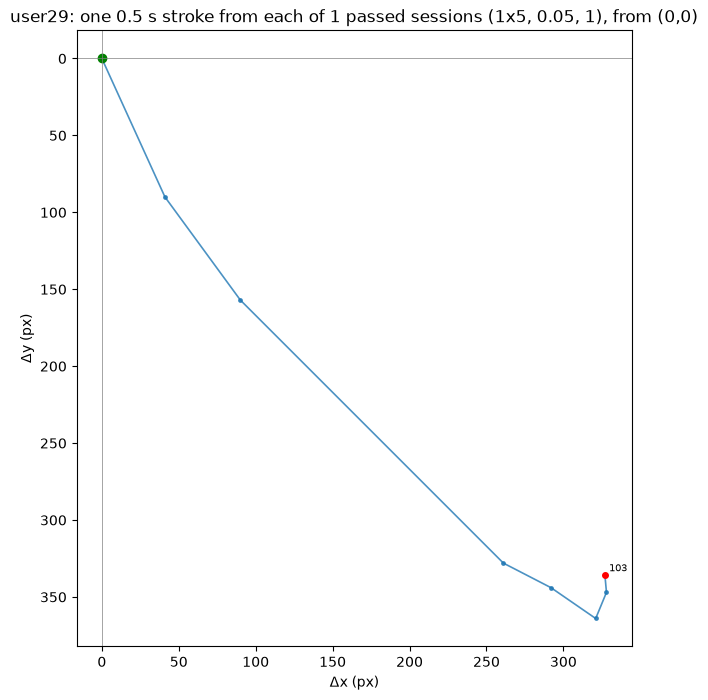

,session,stroke,kind,points,duration_s,end_dx,end_dy
position,,,,,,,
103,session_8423566466,0,move,8,0.5,327,336


1x5 user29: 1 passed sessions, 1 strokes of 0.5 s registered


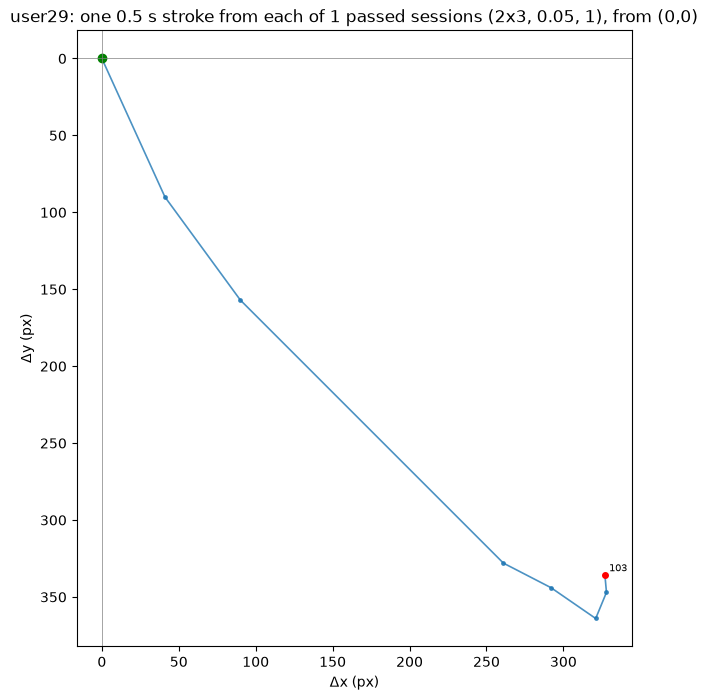

,session,stroke,kind,points,duration_s,end_dx,end_dy
position,,,,,,,
103,session_8423566466,0,move,8,0.5,327,336


2x3 user29: 1 passed sessions, 1 strokes of 0.5 s registered


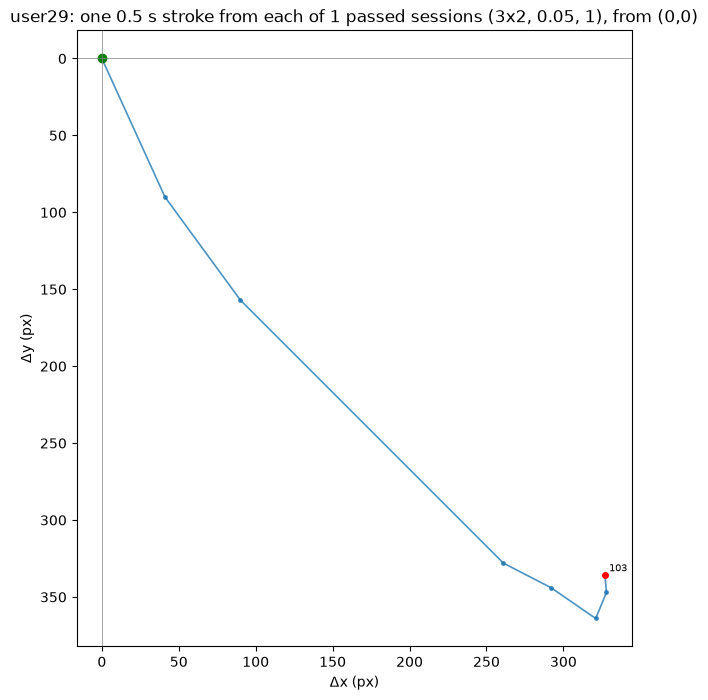

,session,stroke,kind,points,duration_s,end_dx,end_dy
position,,,,,,,
103,session_8423566466,0,move,8,0.5,327,336


3x2 user29: 1 passed sessions, 1 strokes of 0.5 s registered


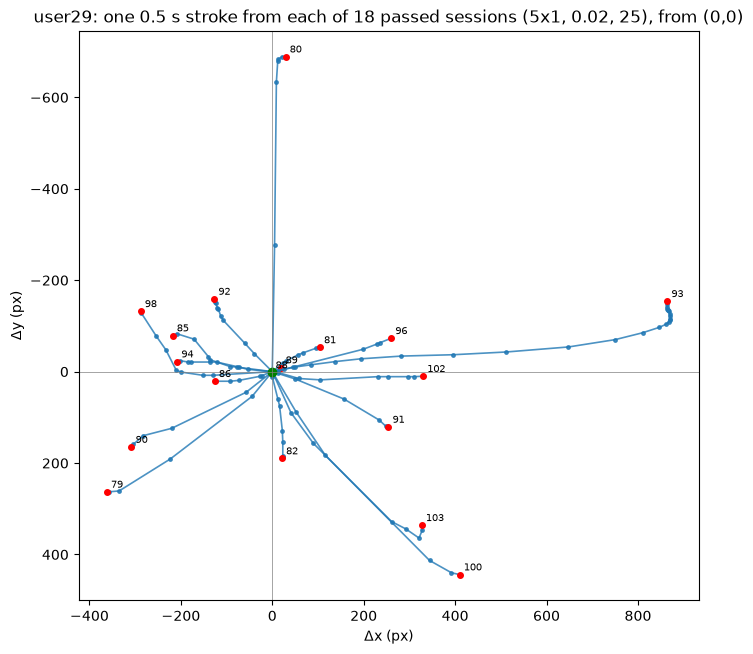

,session,stroke,kind,points,duration_s,end_dx,end_dy
position,,,,,,,
79,session_1944751204,0,move,6,0.5,-362,263
80,session_8627031256,0,move,7,0.5,29,-689
81,session_6711930717,0,move,8,0.5,104,-53
82,session_4725412166,0,move,9,0.5,21,190
85,session_3928232103,0,move,8,0.5,-218,-79
86,session_4746240778,0,move,9,0.5,-126,21
88,session_4858337259,0,move,4,0.5,-2,2
89,session_1778570235,0,move,4,0.5,20,-9
90,session_9660454797,0,move,6,0.5,-308,165


5x1 user29: 18 passed sessions, 18 strokes of 0.5 s registered


5x1 user23: 11 passed sessions, 11 strokes of 0.5 s registered


5x1 user20: 23 passed sessions, 23 strokes of 0.5 s registered


5x1 user15: 9 passed sessions, 9 strokes of 0.5 s registered


5x1 user9: 23 passed sessions, 23 strokes of 0.5 s registered


5x1 user16: 12 passed sessions, 12 strokes of 0.5 s registered


99 strokes registered from 99 passed sessions
Output: /home/tin/thesis-mouse-biometrics/experiment_earl/runs/19399f/passed_strokes_0.5s/


In [5]:
import matplotlib.pyplot as plt
from IPython.display import display

POINT_COLUMNS = ["stroke", "point", "x", "y", "t_s"]


def session_points(user: str, name: str, config: dict) -> tuple[pd.DataFrame, dict[int, str]]:
    """Every recorded point of a session's strokes, cut as in the matching (segment), and each stroke's kind."""
    points, kinds = [], {}
    for i, (chunk, kind) in enumerate(segment(load_session(ROOT / config["dataset_dir"] / user / name), config)):
        x, y, t = chunk.T
        points.append(pd.DataFrame({"stroke": i, "point": np.arange(len(chunk)), "x": x.astype(int), "y": y.astype(int),
                                    "t_s": t.round(3)}))
        kinds[i] = KIND_NAMES[kind]
    return (pd.concat(points, ignore_index=True) if points else pd.DataFrame(columns=POINT_COLUMNS)), kinds


def trim(points: pd.DataFrame, window: float) -> pd.DataFrame:
    """Points within the first `window` seconds of their stroke."""
    return points[points["t_s"] - points.groupby("stroke")["t_s"].transform("first") <= window]


def cut_at(stroke: pd.DataFrame, window: float) -> pd.DataFrame:
    """A stroke's points within its first `window` seconds, ending with a point at exactly `window` s (linear
    interpolation between the recorded points around it, rounded to whole pixels)."""
    t = stroke["t_s"] - stroke["t_s"].iloc[0]
    kept = stroke[t <= window]
    if t.iloc[len(kept) - 1] < window:
        before, after = stroke.iloc[len(kept) - 1], stroke.iloc[len(kept)]
        f = (window - t.iloc[len(kept) - 1]) / (t.iloc[len(kept)] - t.iloc[len(kept) - 1])
        end = {"stroke": before["stroke"], "point": len(kept), "x": int(round(before["x"] + f * (after["x"] - before["x"]))),
               "y": int(round(before["y"] + f * (after["y"] - before["y"]))), "t_s": round(stroke["t_s"].iloc[0] + window, 3)}
        kept = pd.concat([kept, pd.DataFrame([end])], ignore_index=True)
    return kept


def plot_from_origin(strokes: list, title: str, path: Path, show: bool = False) -> None:
    """Strokes shifted to start at (0,0), each end marked and labelled."""
    fig, ax = plt.subplots(figsize=(8, 8))
    for g, kind, label in strokes:
        dx, dy = g["x"] - g["x"].iloc[0], g["y"] - g["y"].iloc[0]
        ax.plot(dx, dy, "-o", ms=2.5, lw=1.2, color="tab:orange" if kind == "drag" else "tab:blue", alpha=.8)
        ax.plot(dx.iloc[-1], dy.iloc[-1], "o", color="red", ms=4)
        ax.annotate(label, (dx.iloc[-1], dy.iloc[-1]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.plot(0, 0, "o", color="green", ms=6)
    ax.axhline(0, c="grey", lw=.5)
    ax.axvline(0, c="grey", lw=.5)
    ax.set_aspect("equal")
    ax.invert_yaxis()  # screen coordinates grow downward
    ax.set(title=title, xlabel="Δx (px)", ylabel="Δy (px)")
    fig.savefig(path, dpi=150, bbox_inches="tight")
    if show:
        plt.show()
    plt.close(fig)


def export_passed(rows: pd.DataFrame, out: Path, window: float, show: bool = False) -> dict:
    """One registered stroke per passed session (its first stroke, trimmed to `window` s): table, points and plot."""
    first = rows.iloc[0]
    strokes, table, kept, skipped = [], [], [], []
    for r in rows.itertuples():
        points, kinds = session_points(r.user, r.session, r.config)
        span = points.groupby("stroke")["t_s"].agg(lambda t: t.iloc[-1] - t.iloc[0])
        long_enough = span[span >= window].index
        if not len(long_enough):
            skipped.append({"split": r.split, "user": r.user, "position": r.position, "session": r.session,
                            "longest_stroke_s": round(float(span.max()), 3)})
            continue
        s = int(long_enough[0])  # the session's first stroke lasting at least `window` seconds
        g = cut_at(points[points["stroke"] == s].reset_index(drop=True), window)
        strokes.append((g, kinds[s], str(r.position)))
        kept.append(g.drop(columns="stroke").assign(position=r.position, session=r.session))
        table.append({"position": r.position, "session": r.session, "stroke": s, "kind": kinds[s], "points": len(g),
                      "duration_s": round(float(g["t_s"].iloc[-1] - g["t_s"].iloc[0]), 3),
                      "end_dx": int(g["x"].iloc[-1] - g["x"].iloc[0]), "end_dy": int(g["y"].iloc[-1] - g["y"].iloc[0])})
    write_csv(pd.DataFrame(table), out / "first_strokes.csv")
    write_csv(pd.concat(kept, ignore_index=True)[["position", "session", "point", "x", "y", "t_s"]],
              out / f"first_stroke_points_{window:g}s.csv")
    plot_from_origin(strokes, f"{first.user}: one {window:g} s stroke from each of {len(strokes)} passed sessions "
                     f"({first.split}, {first.sensitivity}, {first.sessions}), from (0,0)",
                     out / f"first_stroke_{window:g}s.png", show)
    if show:
        display(pd.DataFrame(table).set_index("position"))
    return {"split": first.split, "kind": first.kind, "user": first.user, "passed_sessions": len(rows),
            "strokes": len(strokes), "skipped": skipped}


group = group_folder()
window = PASSED_STROKES["window_s"]
if not (group / "best" / "best_sessions.csv").exists():
    print(f"No {group / 'best' / 'best_sessions.csv'}: run earl_simulation.ipynb (sections 3-5) with the same SETTINGS first")
else:
    out = group / f"passed_strokes_{window:g}s"
    if out.exists():
        shutil.rmtree(out)
    results = pd.read_csv(group / "best" / "best_sessions.csv")  # the simulation's results at the best setting
    passed = results[results["passed"]].copy()
    passed["config"] = [yaml.safe_load((group / run / "config.yaml").read_text()) for run in passed["run"]]
    summary = []
    for (split, user), rows in passed.groupby(["split", "user"], sort=False):
        summary.append(export_passed(rows, out / split / user, window, user in PASSED_STROKES["show"]))
        print(f"{split} {user}: {len(rows)} passed sessions, {summary[-1]['strokes']} strokes of {window:g} s "
              f"registered", flush=True)
    skipped = [s for row in summary for s in row["skipped"]]
    if skipped:
        print(f"{len(skipped)} passed sessions have no stroke lasting {window:g} s, none registered:")
        display(pd.DataFrame(skipped))
    print(f"{sum(row['strokes'] for row in summary)} strokes registered from {len(passed)} passed sessions")
    print(f"Output: {out}/")

## 3. Mixed: legitimate and impostor sessions together

Per split's best setting, **every** tested session (accepted or not) of **every** user, legitimate and impostor, on one
plot, from the simulation's `best/best_sessions.csv` only. Same stroke process as section 2: one stroke per
session, the first lasting at least `window_s`, cut to exactly `window_s`, shifted to start at (0,0).

Colour = role: **blue = legitimate**, **red = impostor**. If the method separated users, blue and red would
fall in different places.

Writes `runs/<hash>/mixed_strokes_<window>s/<split>/`: `strokes.csv` (one row per session: user, kind, library,
position, session, registered stroke), `stroke_points_<window>s.csv` and
`strokes_<window>s.png`.

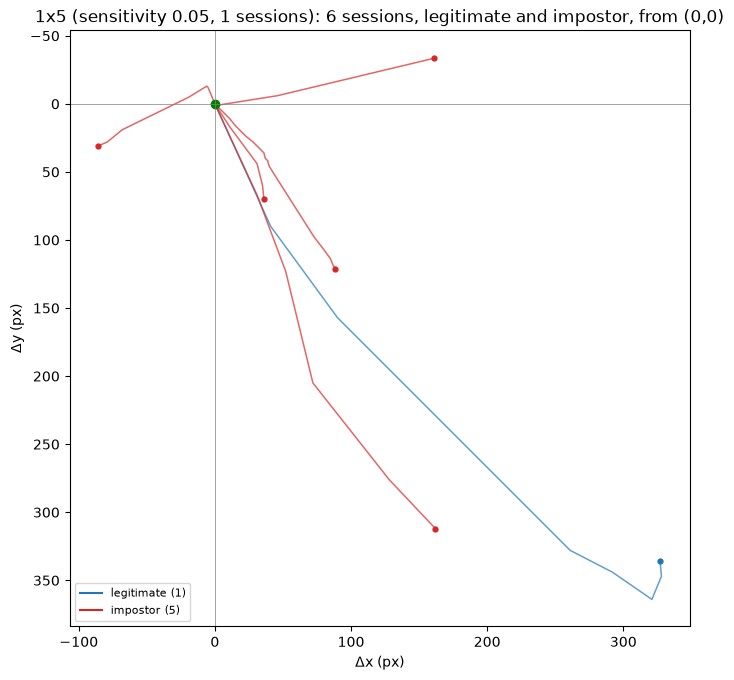

1x5: 5 impostor, 1 legitimate


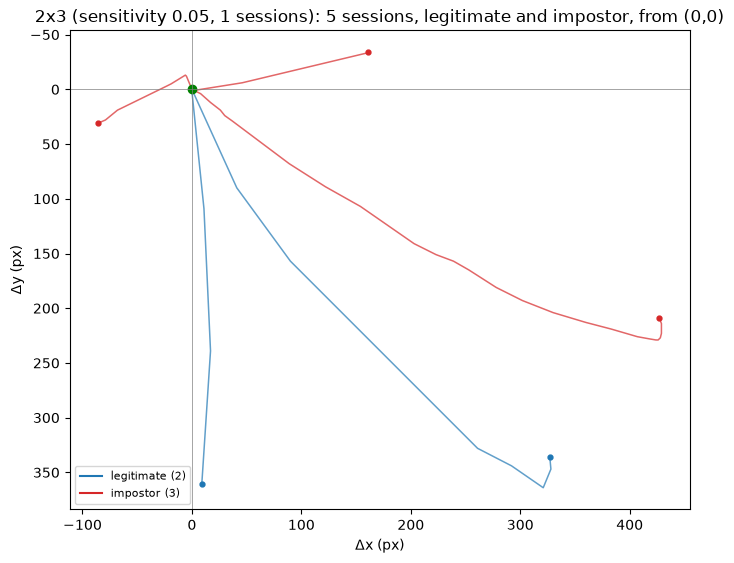

2x3: 3 impostor, 2 legitimate


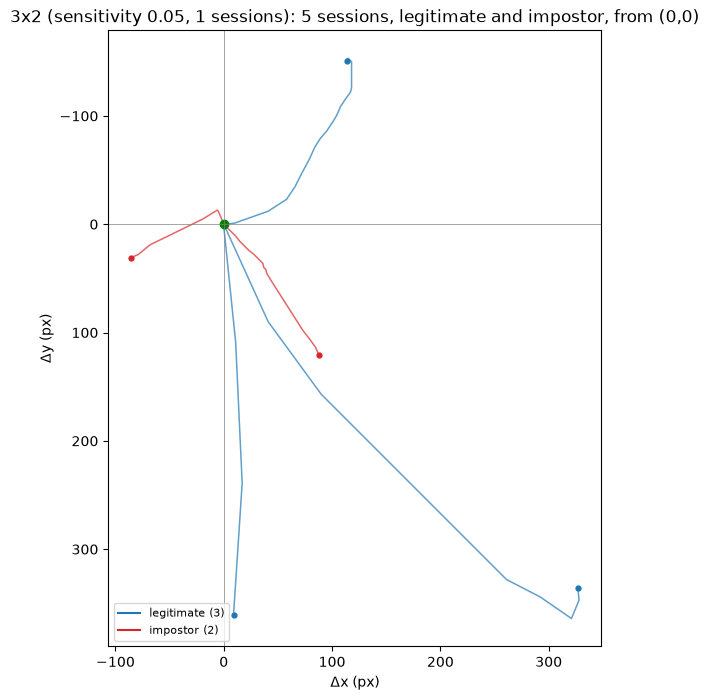

3x2: 3 legitimate, 2 impostor


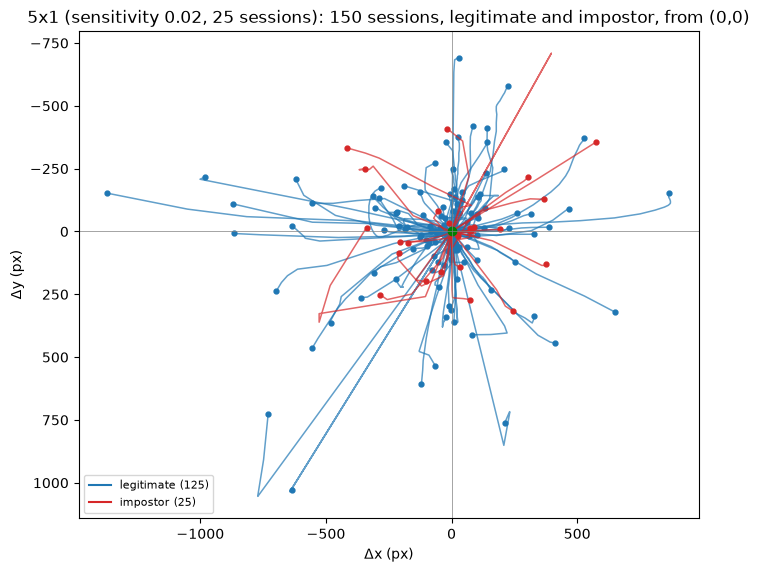

5x1: 125 legitimate, 25 impostor
Output: /home/tin/thesis-mouse-biometrics/experiment_earl/runs/19399f/mixed_strokes_0.5s/


In [6]:
def register_stroke(user: str, session: str, config: dict, window: float):
    """The session's first stroke lasting at least `window` s, cut to exactly `window` s (None if it has none)."""
    points, kinds = session_points(user, session, config)
    span = points.groupby("stroke")["t_s"].agg(lambda t: t.iloc[-1] - t.iloc[0])
    long_enough = span[span >= window].index
    if not len(long_enough):
        return None, None, None
    s = int(long_enough[0])
    return s, kinds[s], cut_at(points[points["stroke"] == s].reset_index(drop=True), window)


ROLE_COLORS = {"legitimate": "tab:blue", "impostor": "tab:red"}


def plot_mixed(strokes: list, title: str, path: Path) -> None:
    """Strokes from (0,0), coloured by role: legitimate blue, impostor red; legend with counts."""
    fig, ax = plt.subplots(figsize=(8, 8))
    for g, kind, _ in strokes:
        dx, dy = g["x"] - g["x"].iloc[0], g["y"] - g["y"].iloc[0]
        ax.plot(dx, dy, lw=1.1, color=ROLE_COLORS[kind], alpha=.7)
        ax.plot(dx.iloc[-1], dy.iloc[-1], "o", color=ROLE_COLORS[kind], ms=3.5)
    for kind in ROLE_COLORS:
        n = sum(k == kind for _, k, _ in strokes)
        if n:
            ax.plot([], [], color=ROLE_COLORS[kind], label=f"{kind} ({n})")
    ax.plot(0, 0, "o", color="green", ms=6)
    ax.axhline(0, c="grey", lw=.5)
    ax.axvline(0, c="grey", lw=.5)
    ax.set_aspect("equal")
    ax.invert_yaxis()  # screen coordinates grow downward
    ax.legend(loc="lower left", fontsize=8)
    ax.set(title=title, xlabel="Δx (px)", ylabel="Δy (px)")
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


group = group_folder()
window = PASSED_STROKES["window_s"]
tested = pd.read_csv(group / "best" / "best_sessions.csv")
out = group / f"mixed_strokes_{window:g}s"
if out.exists():
    shutil.rmtree(out)
for split, sessions in tested.groupby("split", sort=False):
    config = yaml.safe_load((group / sessions["run"].iloc[0] / "config.yaml").read_text())
    table, strokes, points = [], [], []
    for r in sessions.itertuples():
        stroke, stroke_kind, g = register_stroke(r.user, r.session, config, window)
        if g is None:
            print(f"{split} {r.user} {r.session}: no stroke lasting {window:g} s, left out")
            continue
        table.append({"user": r.user, "kind": r.kind, "profile": r.profile, "position": r.position, "session": r.session,
                      "stroke": stroke, "stroke_kind": stroke_kind, "points": len(g),
                      "end_dx": int(g["x"].iloc[-1] - g["x"].iloc[0]), "end_dy": int(g["y"].iloc[-1] - g["y"].iloc[0])})
        strokes.append((g, r.kind, r.passed))
        points.append(g.drop(columns="stroke").assign(user=r.user, kind=r.kind, position=r.position, session=r.session))
    write_csv(pd.DataFrame(table), out / split / "strokes.csv")
    write_csv(pd.concat(points, ignore_index=True)[["user", "kind", "position", "session", "point", "x", "y", "t_s"]], out / split / f"stroke_points_{window:g}s.csv")
    plot_mixed(strokes, f"{split} (sensitivity {sessions['sensitivity'].iloc[0]}, {sessions['sessions'].iloc[0]} sessions): "
               f"{len(strokes)} sessions, legitimate and impostor, from (0,0)", out / split / f"strokes_{window:g}s.png")
    print(f"{split}: " + ", ".join(f"{n} {kind}" for kind, n in pd.DataFrame(table)["kind"].value_counts().items()))
print(f"Output: {out}/")